In [25]:
import hashlib
import json
from dataclasses import dataclass
from pathlib import Path

import dask
import geopandas as gpd
import intake
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import shapely
import xarray as xr
from IPython.display import display as show

In [26]:
# INPUT_PATH = Path("data/input/2020/mx_man20gw.shp")
INPUT_PATH = Path("data/input/master_hex_10km.gpkg")
OUTPUT_DIR = Path("data/output/historical_sst")

# URL con el catálogo de datos CMIP6
CATALOG_URL = "https://storage.googleapis.com/cmip6/pangeo-cmip6.json"

# Rango de fechas para el análisis histórico (se tiene una observación por mes)
START_YEAR = 1982
END_YEAR = 2014
MONTHS = pd.period_range(f"{START_YEAR}-01", f"{END_YEAR}-12", freq="M")

# Si la celda en la que cae un punto no tiene valor de temperatura (por ejemplo,
# si está en tierra), se busca una celda cercana. Este es el radio máximo de búsqueda
# en kilómetros.
CUTOFF_KM = 50.0

# Sistema de referencia de coordenadas para calcular áreas y distancias
AREA_CRS = "EPSG:6933"
DISTANCE_CRS = "EPSG:6372"

MAX_LATITUDE = 90.0

Los píxeles de los rasters miden 1 grado x 1 grado. Muchos polígonos caen dentro de un mismo píxel. Esta clase sirve para almacenar la relación entre los píxeles y los polígonos que caen dentro de ellos. Se usa para que los archivos de salida no sean tan pesados.

In [27]:
@dataclass
class GridMapping:
    grid_id: str
    spatial_dims: tuple[str, str]
    pixels: pd.DataFrame
    relationships: pd.DataFrame

## Entradas

In [28]:
# # Polígonos de manglares
# gdf = (
#     gpd.read_file(INPUT_PATH)
#     .to_crs("EPSG:4326")
#     .reset_index(drop=True)
#     .assign(
#         # Identificador numérico
#         region_id=lambda frame: pd.to_numeric(frame.cov_id, errors="raise").astype(
#             "int64"
#         ),
#         area_m2=lambda frame: gpd.GeoDataFrame(frame).to_crs(AREA_CRS).area,
#     )
# )

# # Punto dentro de cada polígono para calcular distancias después
# roi_points = gdf["geometry"].representative_point()

In [29]:
# Polígonos de la cuadrícula hexagonal
gdf = (
    gpd.read_file(INPUT_PATH)
    .to_crs("EPSG:4326")
    .reset_index(drop=True)
    .dropna(subset=["hex_id"])
    .assign(
        # Mapeamos tu columna hex_id directamente a region_id preservando el texto
        region_id=lambda frame: frame["hex_id"],
        area_m2=lambda frame: gpd.GeoDataFrame(frame).to_crs(AREA_CRS).area,
    )
)

# Punto dentro de cada polígono para calcular distancias después
roi_points = gdf["geometry"].representative_point()

Cargamos el catálogo con todos los experimentos.

In [30]:
catalog = intake.open_esm_datastore(CATALOG_URL)

Buscamos en el catálogo:

- `activity_id="ScenarioMIP"`: `ScenarioMIP` son predicciones a futuro bajo los escenarios base de SSPs.
- `experiment_id="ssp370"`: Seleccionamos el SSP3-7.0
- `variable_id="tos"`: Nos quedamos con los experimentos que reportan la temperatura superficial del mar (`tos`)
- `table_id="Omon"`: Nos quedamos con los experimentos que reportan la temperatura con una periodicidad mensual (también hay experimentos que la reportan por día)

In [31]:
future = (
    catalog.search(
        activity_id="ScenarioMIP",
        experiment_id="ssp370",
        variable_id="tos",
        table_id="Omon",
    )
    .df.copy()
    .sort_values(["source_id", "member_id"])
    .reset_index(drop=True)
)
future.head(10)

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,ScenarioMIP,CSIRO-ARCCSS,ACCESS-CM2,ssp370,r1i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...,<NA>,20191108
1,ScenarioMIP,CSIRO-ARCCSS,ACCESS-CM2,ssp370,r2i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...,<NA>,20200303
2,ScenarioMIP,CSIRO-ARCCSS,ACCESS-CM2,ssp370,r3i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...,<NA>,20200428
3,ScenarioMIP,AWI,AWI-CM-1-1-MR,ssp370,r1i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/AWI/AWI-CM-1-1-MR...,<NA>,20181218
4,ScenarioMIP,AWI,AWI-CM-1-1-MR,ssp370,r2i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/AWI/AWI-CM-1-1-MR...,<NA>,20181218
5,ScenarioMIP,AWI,AWI-CM-1-1-MR,ssp370,r3i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/AWI/AWI-CM-1-1-MR...,<NA>,20181218
6,ScenarioMIP,AWI,AWI-CM-1-1-MR,ssp370,r4i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/AWI/AWI-CM-1-1-MR...,<NA>,20181218
7,ScenarioMIP,AWI,AWI-CM-1-1-MR,ssp370,r5i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/AWI/AWI-CM-1-1-MR...,<NA>,20181218
8,ScenarioMIP,BCC,BCC-CSM2-MR,ssp370,r1i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/BCC/BCC-CSM2-MR/s...,<NA>,20190319
9,ScenarioMIP,CAMS,CAMS-CSM1-0,ssp370,r1i1p1f1,Omon,tos,gn,gs://cmip6/CMIP6/ScenarioMIP/CAMS/CAMS-CSM1-0/...,<NA>,20190708


In [32]:
print(
    f"Número de experimentos distintos que cumplen nuestros requisitos: {len(future['source_id'].unique())}"
)

Número de experimentos distintos que cumplen nuestros requisitos: 39


Cada `source_id` es un forecast realizado por un experimento distinto. Varían en las suposiciones que hacen; el rango de tiempo; la resolución espacial y temporal; y las temperaturas que reportan. Necesitamos una manera de determinar cuál es el mejor conjunto de datos para nuestros propósitos. 

Aparte de publicar forecasts para años en el futuro (2030, 2040, etc.), varios experimentos también publican datos de años pasados (2000 a 2020) aproximados con su mismo modelo. Estos datos nos dan una manera de medir el desempeño del modelo en nuestra región de interés: podemos comparar estas "predicciones históricas" con mediciones reales, y determinar cuál es el modelo que reporta el menor error.

Entonces, necesitamos obtener los experimentos históricos para los *los mismos experimentos que encontramos anteriormente*. No tiene caso analizar un histórico si no tiene también un forecast. Para esto, usamos la siguiente sintaxis:

- `activity_id="CMIP"`: `CMIP` datos históricos predichos con los mismos modelos que los experimentos de `ScenarioMIP`.
- `experiment_id="historical"`: Lo mismo
- `source_id=future.df["source_id"].unique().tolist()`: Nos quedamos con los experimentos históricos que corresponden a los experimentos futuros que encontramos antes.
- `grid_label="gr"`: Estos experimentos están reproyectados a `EPSG:4326` (aunque su resolución puede variar). Ayuda a que sea más fácil procesarlos y compararlos entre sí.

In [33]:
historical = (
    catalog.search(
        activity_id="CMIP",
        experiment_id="historical",
        variable_id="tos",
        table_id="Omon",
        source_id=future["source_id"].unique().tolist(),
        grid_label="gr",
    )
    .df.copy()
    .sort_values(["source_id", "member_id"])
    .reset_index(drop=True)
)

historical.head(5)

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,CMIP,NCAR,CESM2,historical,r10i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,<NA>,20190313
1,CMIP,NCAR,CESM2,historical,r11i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,<NA>,20190514
2,CMIP,NCAR,CESM2,historical,r1i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r1...,<NA>,20190308
3,CMIP,NCAR,CESM2,historical,r2i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r2...,<NA>,20190308
4,CMIP,NCAR,CESM2,historical,r3i1p1f1,Omon,tos,gr,gs://cmip6/CMIP6/CMIP/NCAR/CESM2/historical/r3...,<NA>,20190308


In [34]:
print(
    f"Número de experimentos históricos encontrados: {len(historical['source_id'].unique())}"
)
print(
    f"Nombres de experimentos que tienen tanto histórico como forecast: {historical['source_id'].unique().tolist()}"
)

Número de experimentos históricos encontrados: 7
Nombres de experimentos que tienen tanto histórico como forecast: ['CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'GFDL-ESM4', 'KACE-1-0-G', 'MRI-ESM2-0']


## Regiones de interés a pixeles

Los rasters que reportan los experimentos pueden tener distintas resoluciones. Esto es importante a la hora de comparar los datos entre sí, y también a la hora de compararlos con mediciones reales. En esta sección, los limpiamos y reproyectamos.

In [35]:
# Algunos experimentos llaman a sus coordenadas (lat, lon) y otros
# (latitude, longitude). Esta función ayuda a encontrar ambos tipos.
def geographic_coordinates(dataset: xr.Dataset) -> tuple[str, str]:
    for lat_name, lon_name in [("latitude", "longitude"), ("lat", "lon")]:
        if lat_name in dataset and lon_name in dataset:
            return lat_name, lon_name
    message = "No recognized geographic latitude/longitude coordinates"
    raise ValueError(message)


# Bounds de las celdas/píxeles
def coordinate_bounds(
    dataset: xr.Dataset, name: str, dims: tuple[str, ...]
) -> np.ndarray:
    bounds_name = dataset[name].attrs.get("bounds")
    bounds = dataset[bounds_name]
    extra = [dim for dim in bounds.dims if dim not in dims]
    return np.asarray(bounds.transpose(*dims, extra[0]).values, dtype="float64")

In [36]:
# Esta función garantiza que todos los rasters tengan los mismos nombres
# de dimensiones, y corrige errores de longitud de coordenadas y bounds
# (por ejemplo, convierte la longitud de 0 a 360 a -180 a 180)


def grid_arrays(
    dataset: xr.Dataset,
) -> tuple[tuple[str, str], np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    y_dim, x_dim = (str(dim) for dim in dataset["tos"].dims if dim != "time")
    spatial = (y_dim, x_dim)

    lat_name, lon_name = geographic_coordinates(dataset)
    latitude, longitude = dataset[lat_name], dataset[lon_name]

    if latitude.ndim == 1 and longitude.ndim == 1:
        lat = np.asarray(latitude.values, dtype="float64")
        lon = np.asarray(longitude.values, dtype="float64")

        lat_bounds = coordinate_bounds(
            dataset, lat_name, tuple(str(dim) for dim in latitude.dims)
        )
        lon_bounds = coordinate_bounds(
            dataset, lon_name, tuple(str(dim) for dim in longitude.dims)
        )

        center_lon, center_lat = np.meshgrid(lon, lat)
        vertex_lon = np.broadcast_to(
            lon_bounds[:, [0, 1, 1, 0]][None, :, :], (*center_lon.shape, 4)
        ).copy()
        vertex_lat = np.broadcast_to(
            lat_bounds[:, [0, 0, 1, 1]][:, None, :], (*center_lat.shape, 4)
        ).copy()

    else:
        center_lat = np.asarray(latitude.transpose(*spatial).values, dtype="float64")
        center_lon = np.asarray(longitude.transpose(*spatial).values, dtype="float64")
        vertex_lat = coordinate_bounds(dataset, lat_name, spatial)
        vertex_lon = coordinate_bounds(dataset, lon_name, spatial)
    center_lon = (center_lon + 180) % 360 - 180
    vertex_lon = (
        center_lon[..., None] + (vertex_lon - center_lon[..., None] + 180) % 360 - 180
    )
    return spatial, center_lat, center_lon, vertex_lat, vertex_lon


# Muchos experimentos usan exactamente la misma resolución espacial y bounds.
# Esta función sirve para detectar si este es el caso. Genera un identificador
# único con base en ciertos atributos del raster. Si dos rasters tienen el
# mismo identificador, sabemos que sus píxeles se empalman perfectamente, y no
# tenemos que reproyectarlos para compararlos entre sí. Nota que esto no
# significa que los valores de temperatura sean iguales, solo que los píxeles
# coinciden.
def grid_fingerprint(spatial: tuple[str, str], arrays: tuple[np.ndarray, ...]) -> str:
    digest = hashlib.sha256(json.dumps(spatial).encode())
    for array in arrays:
        digest.update(json.dumps(array.shape).encode())
        digest.update(np.ascontiguousarray(array, dtype="<f8").tobytes())
    return digest.hexdigest()


# Esta función genera un GeoDataFrame con los píxeles de un raster como polígonos,
# para encontrar en qué píxel cae cada polígono de manglar, y también para
# encontrar píxeles cercanos si el polígono cae en un píxel sin valor de temperatura.
def grid_cells(
    center_lat: np.ndarray,
    center_lon: np.ndarray,
    vertex_lat: np.ndarray,
    vertex_lon: np.ndarray,
) -> gpd.GeoDataFrame:
    valid = np.isfinite(vertex_lat).all(axis=-1) & np.isfinite(vertex_lon).all(axis=-1)
    valid &= (np.abs(vertex_lat) <= MAX_LATITUDE).all(axis=-1)
    valid &= np.isfinite(center_lon) & (np.abs(center_lat) < MAX_LATITUDE)
    row, col = np.nonzero(valid)
    return gpd.GeoDataFrame(
        {
            "pixel_id": row * center_lon.shape[1] + col,
            "row": row,
            "col": col,
            "longitude": center_lon[valid],
            "latitude": center_lat[valid],
        },
        geometry=shapely.polygons(
            np.stack([vertex_lon[valid], vertex_lat[valid]], axis=-1)
        ),
        crs="EPSG:4326",
    )

In [37]:
# Hace el emparejamiento entre los polígonos de manglar y los píxeles de un
# cierto raster
def relationship_pairs(cells: gpd.GeoDataFrame) -> pd.DataFrame:
    intersections = (
        gdf[["geometry"]]
        .rename_axis("roi_index")
        .sjoin(cells[["geometry"]].rename_axis("cell_index"), predicate="intersects")
        .reset_index()
        .drop(columns="geometry")
    )
    points = (
        gpd.GeoDataFrame(geometry=roi_points, crs=gdf.crs)
        .to_crs(DISTANCE_CRS)
        .rename_axis("roi_index")
    )
    centers = (
        gpd.GeoDataFrame(
            geometry=gpd.points_from_xy(cells.longitude, cells.latitude),
            crs=cells.crs,
        )
        .to_crs(DISTANCE_CRS)
        .rename_axis("cell_index")
    )
    nearby = (
        points.sjoin(centers, predicate="dwithin", distance=CUTOFF_KM * 1000)
        .reset_index()
        .drop(columns="geometry")
    )
    pairs = (
        pd.concat([intersections, nearby], ignore_index=True)
        .drop_duplicates()
        .reset_index(drop=True)
    )
    distances = (
        points.geometry.iloc[pairs.roi_index]
        .reset_index(drop=True)
        .distance(
            centers.geometry.iloc[pairs.cell_index].reset_index(drop=True), align=False
        )
    )
    return pairs.assign(distance_km=distances / 1000)


# Hace el emparejamiento final entre todos los polígonos y todos los rasters
def create_relationships(cells: gpd.GeoDataFrame, grid_id: str) -> pd.DataFrame:
    pairs = relationship_pairs(cells)
    roi_index = pairs["roi_index"].to_numpy()
    cell_index = pairs["cell_index"].to_numpy()
    roi_geometry = gdf.geometry.to_numpy()[roi_index]
    cell_geometry = cells.geometry.to_numpy()[cell_index]
    intersects = shapely.intersects(roi_geometry, cell_geometry)
    overlap = shapely.intersection(roi_geometry, cell_geometry)
    areas = gpd.GeoSeries(overlap, crs="EPSG:4326").to_crs(AREA_CRS).area.to_numpy()
    return (
        pd.DataFrame(cells.drop(columns="geometry").iloc[cell_index])
        .reset_index(drop=True)
        .assign(
            grid_id=grid_id,
            region_id=gdf.region_id.to_numpy()[roi_index],
            intersects_roi=intersects,
            within_cutoff=pairs.distance_km <= CUTOFF_KM,
            intersection_area_m2=areas,
            roi_area_fraction=areas / gdf.area_m2.to_numpy()[roi_index],
            distance_km=pairs.distance_km,
        )
        .sort_values(["region_id", "pixel_id"])
        .reset_index(drop=True)
    )


# Esta función genera las relaciones entre manglares y píxeles usando la función
# create_relationships. Si dos rasters tienen la misma resolución y bounds,
# entonces los manglares caerán en exactamente los mismos píxeles. Para evitar perder
# tiempo, esta función detecta si ya se generó un mapeo para un raster con
# los mismos píxeles, usando la función grid_fingerprint.
def get_mapping(dataset: xr.Dataset, cache: dict[str, GridMapping]) -> GridMapping:
    spatial, center_lat, center_lon, vertex_lat, vertex_lon = grid_arrays(dataset)
    grid_id = grid_fingerprint(
        spatial, (center_lat, center_lon, vertex_lat, vertex_lon)
    )
    if grid_id not in cache:
        cells = grid_cells(center_lat, center_lon, vertex_lat, vertex_lon)
        relationships = create_relationships(cells, grid_id)
        pixels = pd.DataFrame(
            cells.loc[cells["pixel_id"].isin(relationships["pixel_id"])].drop(
                columns="geometry"
            )
        )
        pixels = pixels.sort_values("pixel_id").reset_index(drop=True)
        cache[grid_id] = GridMapping(grid_id, spatial, pixels, relationships)
    return cache[grid_id]

## Extracción

En esta sección, extraemos los datos de los experimentos y los guardamos en tablas. La verdad está muy zzz, no lo voy a explicar c: Lo importante es que cada experimento tiene su propia tabla en data/output. Sin embargo, estas tablas no se pueden importar en QGIS así nada más, ya que no nos dicen la temperatura del polígono de manglar, sino del píxel del raster asociado. Esto lo hacemos para guardar espacio, ya que hay ~100 pixeles vs. 12,000 polígonos de manglares. De cualquier manera, usando estos datos es muy fácil generar polígonos de manglares con la temperatura (lo hacemos al final de la libreta).

In [38]:
def file_metadata(source_id: str, member_id: str) -> dict[bytes, bytes]:
    return {b"source_id": source_id.encode(), b"member_id": member_id.encode()}


def arrow_table(frame: pd.DataFrame, metadata: dict[bytes, bytes]) -> pa.Table:
    return pa.Table.from_pandas(frame, preserve_index=False).replace_schema_metadata(
        metadata
    )


def monthly_coordinates(
    dataset: xr.Dataset,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    years = np.asarray(dataset["time"].dt.year.values, dtype="int16")
    months = np.asarray(dataset["time"].dt.month.values, dtype="int8")
    selected = (years >= START_YEAR) & (years <= END_YEAR)
    return years, months, selected


def temperature_frame(
    mapping: GridMapping,
    years: np.ndarray,
    months: np.ndarray,
    values: np.ndarray,
) -> pd.DataFrame:
    count = len(mapping.pixels)
    return pd.DataFrame(
        {
            "grid_id": mapping.grid_id,
            "pixel_id": np.tile(mapping.pixels["pixel_id"].to_numpy(), len(years)),
            "year": np.repeat(np.asarray(years, dtype="int16"), count),
            "month": np.repeat(np.asarray(months, dtype="int8"), count),
            "temperature_c": np.asarray(values, dtype="float64").reshape(-1),
        }
    )


def source_block(
    dataset: xr.Dataset, mapping: GridMapping, indices: np.ndarray
) -> np.ndarray:
    y_dim, x_dim = mapping.spatial_dims
    indexers = {
        "time": indices,
        y_dim: xr.DataArray(mapping.pixels["row"].to_numpy(), dims="pixel"),
        x_dim: xr.DataArray(mapping.pixels["col"].to_numpy(), dims="pixel"),
    }
    with dask.config.set(scheduler="synchronous"):
        values = (
            dataset["tos"]
            .isel(indexers)
            .transpose("time", "pixel")
            .compute()
            .to_numpy()
        )
    return np.asarray(values, dtype="float64")


def write_temperature_file(
    dataset: xr.Dataset, mapping: GridMapping, path: Path, metadata: dict[bytes, bytes]
) -> None:
    years, months, selected = monthly_coordinates(dataset)
    present_keys = set(zip(years[selected], months[selected], strict=True))
    schema = pa.schema(
        [
            ("grid_id", pa.string()),
            ("pixel_id", pa.int64()),
            ("year", pa.int16()),
            ("month", pa.int8()),
            ("temperature_c", pa.float64()),
        ],
        metadata=metadata,
    )
    chunks = dataset["tos"].chunksizes.get("time", (dataset.sizes["time"],))
    offset = 0
    with pq.ParquetWriter(path, schema, compression="zstd") as writer:
        for length in chunks:
            indices = np.flatnonzero(selected[offset : offset + length]) + offset
            offset += length
            if not len(indices):
                continue
            values = source_block(dataset, mapping, indices)
            frame = temperature_frame(mapping, years[indices], months[indices], values)
            writer.write_table(arrow_table(frame, metadata).cast(schema))
        absent = [
            period
            for period in MONTHS
            if (period.year, period.month) not in present_keys
        ]
        if absent:
            values = np.full((len(absent), len(mapping.pixels)), np.nan)
            frame = temperature_frame(
                mapping,
                np.array([p.year for p in absent]),
                np.array([p.month for p in absent]),
                values,
            )
            writer.write_table(arrow_table(frame, metadata).cast(schema))

In [39]:
def output_paths(source_id: str, member_id: str) -> tuple[Path, Path]:
    name = f"{source_id}__{member_id}.parquet"
    temperature_path = OUTPUT_DIR / "temperatures" / name
    mapping_path = OUTPUT_DIR / "roi_pixels" / name
    temperature_path.parent.mkdir(parents=True, exist_ok=True)
    mapping_path.parent.mkdir(parents=True, exist_ok=True)
    return temperature_path, mapping_path


def export_dataset(
    source_id: str, member_id: str, zstore: str, cache: dict[str, GridMapping]
) -> None:
    temperature_path, mapping_path = output_paths(source_id, member_id)
    metadata = file_metadata(source_id, member_id)
    with xr.open_zarr(
        zstore, storage_options={"token": "anon"}, decode_times=True
    ) as dataset:
        mapping = get_mapping(dataset, cache)
        write_temperature_file(dataset, mapping, temperature_path, metadata)
        pq.write_table(
            arrow_table(mapping.relationships, metadata),
            mapping_path,
            compression="zstd",
        )

## Ejecución

Aquí corremos y generamos los archivos.

In [40]:
mapping_cache: dict[str, GridMapping] = {}
for record in historical.to_dict("records"):
    export_dataset(
        str(record["source_id"]),
        str(record["member_id"]),
        str(record["zstore"]),
        mapping_cache,
    )

## Preview

In [41]:
first = historical.iloc[0]
temperature_path, mapping_path = output_paths(
    str(first["source_id"]), str(first["member_id"])
)

Visualizando un ejemplo de tabla de temperaturas por píxel:

In [42]:
show(pd.read_parquet(temperature_path).head(5))

,grid_id,pixel_id,year,month,temperature_c
0,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,36625,1982,1,26.950090
1,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,36980,1982,1,26.434258
2,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,36981,1982,1,26.131519
3,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,36982,1982,1,26.039585
4,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,36983,1982,1,26.225666


Y la tabla relacionada que nos dice qué píxeles corresponden a qué polígonos de manglares:

In [43]:
show(pd.read_parquet(mapping_path).head(5))

,pixel_id,row,col,longitude,latitude,grid_id,region_id,intersects_roi,within_cutoff,intersection_area_m2,roi_area_fraction,distance_km
0,42717,118,237,-122.5,28.5,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,HEX0000001,True,False,8.121787e+07,0.937823,58.759795
1,42718,118,238,-121.5,28.5,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,HEX0000001,True,False,5.384463e+06,0.062174,65.309040
2,42717,118,237,-122.5,28.5,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,HEX0000002,True,True,8.660254e+07,1.000000,47.035975
3,42717,118,237,-122.5,28.5,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,HEX0000003,True,True,8.660254e+07,1.000000,39.454298
4,42717,118,237,-122.5,28.5,8e1439e024e05194334c1968d78d8877a1e051ddcfab75...,HEX0000004,True,True,8.660254e+07,1.000000,38.549115


## Ejemplo de generación de GeoPackage

Exportamos datos de `GFDL-ESM4, r1i1p1f1` para Enero de 1982 (se puede cambiar).

Si un polígono intersecta a varios píxeles, se hace un promedio ponderado por el área de intersección para calcular la temperatura asociada.

In [44]:
example_source_id = "GFDL-ESM4"
example_member_id = "r1i1p1f1"
example_year = 1982
example_month = 1

temperature_path, mapping_path = output_paths(example_source_id, example_member_id)
example_temperatures = pd.read_parquet(
    temperature_path,
    filters=[("year", "==", example_year), ("month", "==", example_month)],
)
example_matches = (
    pd.read_parquet(mapping_path)
    .merge(example_temperatures, on=["grid_id", "pixel_id"], validate="many_to_one")
    .dropna(subset=["temperature_c"])
)

In [45]:
weighted_temperatures = (
    example_matches.loc[lambda frame: frame.intersection_area_m2 > 0]
    .assign(
        weighted_temperature=lambda frame: (
            frame.temperature_c * frame.intersection_area_m2
        )
    )
    .groupby("region_id")
    .agg(
        weighted_temperature=("weighted_temperature", "sum"),
        overlap_area=("intersection_area_m2", "sum"),
    )
    .assign(temperature_c=lambda frame: frame.weighted_temperature / frame.overlap_area)
    .temperature_c
)
nearest_temperatures = (
    example_matches.loc[lambda frame: frame.within_cutoff]
    .sort_values(["region_id", "distance_km", "pixel_id"])
    .drop_duplicates("region_id")
    .set_index("region_id")
    .temperature_c
)
roi_temperatures = gdf.merge(
    weighted_temperatures.combine_first(nearest_temperatures).rename("temperature_c"),
    on="region_id",
    how="left",
    validate="one_to_one",
)
example_path = OUTPUT_DIR / (
    f"{example_source_id}__{example_member_id}__{example_year}-{example_month:02d}.gpkg"
)
roi_temperatures.to_file(
    example_path,
    layer="roi_temperatures",
    driver="GPKG",
    index=False,
    metadata={"source_id": example_source_id, "member_id": example_member_id},
)
show(roi_temperatures[["region_id", "temperature_c"]].head())
example_path

,region_id,temperature_c
0,HEX0000001,16.726395
1,HEX0000002,16.729881
2,HEX0000003,16.729881
3,HEX0000004,16.729881
4,HEX0000005,16.729881


Path('data/output/historical_sst/GFDL-ESM4__r1i1p1f1__1982-01.gpkg')

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

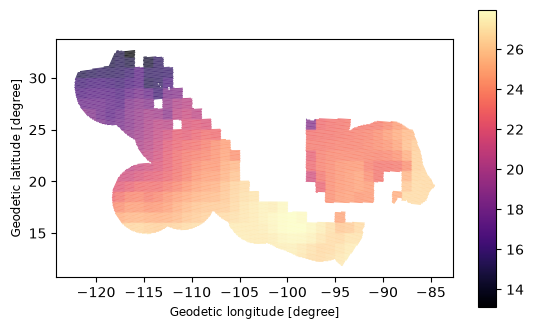

In [47]:
df_example = gpd.read_file(example_path)
df_example.plot(column="temperature_c", cmap="magma", legend=True)